# Barrido en frecuencia de DEP sobre nanopartículas — Fokker-Planck radial

**Experimento:** 30 frecuencias equiespaciadas en escala logarítmica entre 100 kHz y 10 MHz; cada una se aplica durante 2 s, una tras otra. Según la frecuencia la partícula sufre pDEP (atracción al hueco entre electrodos, $r\to 0$) o nDEP (repulsión).

### Campo de electrodos coplanares
Dos electrodos semi-infinitos coplanares separados por un hueco estrecho: en coordenadas polares centradas en el hueco $V(r,\theta)=\theta V_0/\pi$, con $\theta\in[0,\pi]$ (semiplano del fluido). Entonces

$$
\mathbf E = -\frac{1}{r}\partial_\theta V\,\hat\theta = -\frac{V_0}{\pi r}\,\hat\theta,
\qquad |\mathbf E|^2 = \frac{V_0^2}{\pi^2 r^2}\ \propto r^{n},\quad n=-2 .
$$

$|\mathbf E|$ sólo depende de $r$, así que con condición inicial uniforme el problema es radial (las paredes $\theta=0,\pi$ son de flujo nulo) y se puede usar el Fokker-Planck cilíndrico de `fokker_planck.py`. El semiplano sólo cambia la normalización: número por unidad de longitud de electrodo $=\pi\int \phi\, r\,dr / V_p$.

La ley $1/r$ diverge en $r\to0$; el modelo deja de valer a escala del hueco, así que se corta en $r_c$: $|\mathbf E|^2 = V_0^2/(\pi^2\max(r,r_c)^2)$ (sin fuerza para $r<r_c$).

### Energía DEP con apantallamiento
$V_0$ es la **amplitud** (pico) de la tensión AC, $E_{rms}^2=E_0^2/2$:

$$
U(r,\omega) = -2\pi\varepsilon_m a^3\,\mathrm{Re}[K(\omega)]\,S(\Omega)\,E_{rms}^2
= -\pi\varepsilon_m a^3\,\mathrm{Re}[K(\omega)]\,S(\Omega)\,\frac{V_0^2}{\pi^2\max(r,r_c)^2}
$$

- Clausius-Mossotti: $K=\dfrac{\varepsilon_p^*-\varepsilon_m^*}{\varepsilon_p^*+2\varepsilon_m^*}$, con $\varepsilon^*=\varepsilon-i\sigma/\omega$.
- Apantallamiento (polarización de electrodos): $\Omega=\dfrac{\omega\Lambda\varepsilon_m l_c}{\sigma_m\lambda_D}$, $\quad S(\Omega)=\dfrac{\Omega^2}{1+\Omega^2}$.

### Fokker-Planck
$$
\partial_t\phi = -\frac1r\partial_r(rJ),\qquad J = v\,\phi\Big(1-\frac{\phi}{\phi_{max}}\Big) - D\,\partial_r\phi,\qquad
v=-\frac{\partial_r U}{\gamma},\quad \gamma=6\pi\eta a,\quad D=\frac{k_BT}{\gamma}
$$

$\phi$ es la fracción de volumen de partículas; $\phi_{max}$ el empaquetamiento máximo. En $r=R$ hay un reservorio a $\phi_0$ (Dirichlet). Cada frecuencia es un tramo de 2 s con la deriva correspondiente; el perfil final de un tramo es la condición inicial del siguiente.

**Todo en unidades SI.**

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from fokker_planck import RadialFokkerPlanck

plt.rcParams["figure.dpi"] = 110

## 1. Parámetros (SI)

In [2]:
# ---------------------------------------------------------------- constantes
eps0 = 8.8541878128e-12      # F/m
kB   = 1.380649e-23          # J/K
T    = 298.15                # K
kT   = kB * T

# ---------------------------------------------------------------- medio
eps_m = 78.5 * eps0          # permitividad del medio            [F/m]
sig_m = 0.0045                 # conductividad del medio           [S/m]
eta   = 8.9e-4               # viscosidad                        [Pa s]

# ---------------------------------------------------------------- partícula
a     = 50e-9                # radio                             [m]
eps_p = 2.55 * eps0          # permitividad de la partícula      [F/m]
sig_p = 0.007                 # conductividad efectiva partícula  [S/m]  (p.ej. 2 K_s / a)

# ---------------------------------------------------------------- electrodos / campo
V0    = 1.0                  # amplitud (pico) de la tensión entre electrodos  [V]
r_c   = 1e-7                 # radio de corte de la ley 1/r (~ semi-hueco)      [m]

# ---------------------------------------------------------------- apantallamiento
Lam   = 0.25                # Lambda (adimensional)
l_c   = 600e-9                # longitud característica           [m]
lam_D = 30e-9                # longitud de Debye                 [m]

# ---------------------------------------------------------------- suspensión
n0   = 1e11 * 1e6                     # concentración en número [m^-3]  (1e11 mL^-1)
phi0 = n0 * 4/3 * np.pi * a**3        # fracción de volumen inicial / reservorio
phi_max = 0.2               # empaquetamiento máximo

# ---------------------------------------------------------------- experimento
f_min, f_max, n_freq = 100e3, 10e6, 30
t_step  = 2.0                # tiempo por frecuencia             [s]
orden   = "descendente"       # "ascendente" o "descendente"
freqs = np.logspace(np.log10(f_min), np.log10(f_max), n_freq)
if orden == "descendente":
    freqs = freqs[::-1]

# ---------------------------------------------------------------- observable
r_ROI = 1e-6                 # región de interés: 0 < r < r_ROI   [m]

# ---------------------------------------------------------------- numérico
R     = 100e-6               # radio del dominio (reservorio en r=R)  [m]
N     = 2000                 # celdas radiales (dr = R/N)
n_out = 21                   # instantes guardados por frecuencia

## 2. Física: Clausius-Mossotti, apantallamiento y deriva

In [3]:
gamma = 6 * np.pi * eta * a          # fricción de Stokes      [kg/s]
D     = kT / gamma                   # difusión                [m^2/s]
V_p   = 4/3 * np.pi * a**3           # volumen de partícula    [m^3]

def K_CM(f):
    w  = 2 * np.pi * np.asarray(f, float)
    ep = eps_p - 1j * sig_p / w
    em = eps_m - 1j * sig_m / w
    return (ep - em) / (ep + 2 * em)

def Omega(f):
    return 2 * np.pi * np.asarray(f, float) * Lam * eps_m * l_c / (sig_m * lam_D)

def S(f):
    O = Omega(f)
    return O**2 / (1 + O**2)

def A_DEP(f, screening=True):
    # U(r) = -A / max(r, r_c)^2   [A en J m^2];  A > 0: pDEP, A < 0: nDEP
    s = S(f) if screening else 1.0
    return np.pi * eps_m * a**3 * K_CM(f).real * s * V0**2 / np.pi**2

def U_DEP(r, f, screening=True):
    return -A_DEP(f, screening) / np.maximum(np.asarray(r, float), r_c)**2

def drift_DEP(f, screening=True):
    # v = -U'/gamma = -2A / (gamma r^3) para r > r_c, 0 dentro del corte
    A = A_DEP(f, screening)
    def v(r):
        r = np.asarray(r, float)
        return np.where(r > r_c, -2 * A / (gamma * np.maximum(r, r_c)**3), 0.0)
    return v

# frecuencia de cruce (Re K = 0), analítica
num = (sig_p - sig_m) * (sig_p + 2 * sig_m)
den = (eps_m - eps_p) * (eps_p + 2 * eps_m)
f_cross = np.sqrt(num / den) / (2 * np.pi) if num / den > 0 else np.nan

print(f"D           = {D:.3e} m^2/s")
print(f"f_cruce CM  = {f_cross/1e6:.3f} MHz")
print(f"Omega       = {Omega(f_min):.3g} (f_min) ... {Omega(f_max):.3g} (f_max)")
print(f"S           = {S(f_min):.4f} (f_min) ... {S(f_max):.4f} (f_max)")
print(f"U(r_c)/kT   = {U_DEP(r_c, f_min)/kT:.1f} (f_min) ... {U_DEP(r_c, f_max)/kT:.1f} (f_max)")

D           = 4.907e-12 m^2/s
f_cruce CM  = 1.033 MHz
Omega       = 0.485 (f_min) ... 48.5 (f_max)
S           = 0.1906 (f_min) ... 0.9996 (f_max)
U(r_c)/kT   = -19.8 (f_min) ... 306.3 (f_max)


### Respuesta en frecuencia y escalas de tiempo

Con $U=-A/r^2$ la deriva es $\dot r = -2A/(\gamma r^3)$, así que una partícula en $r$ tarda $t = \gamma r^4/(8A)$ en llegar al hueco: en un tramo $t_{step}$ el radio de captura es $r_{cap}=(8|A|t_{step}/\gamma)^{1/4}$. Compárese con la longitud difusiva $\sqrt{4Dt_{step}}$.

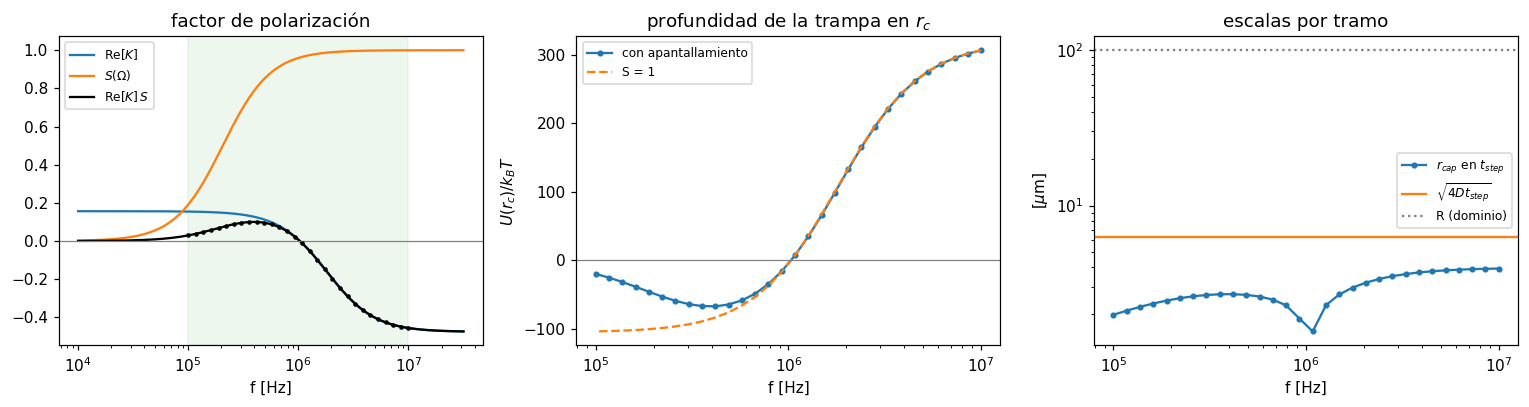

In [4]:
ff = np.logspace(np.log10(f_min) - 1, np.log10(f_max) + 0.5, 400)
r_cap = (8 * np.abs(A_DEP(freqs)) * t_step / gamma)**0.25

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].semilogx(ff, K_CM(ff).real, label=r"Re$[K]$")
ax[0].semilogx(ff, S(ff), label=r"$S(\Omega)$")
ax[0].semilogx(ff, K_CM(ff).real * S(ff), "k", label=r"Re$[K]\,S$")
ax[0].axhline(0, color="gray", lw=0.8)
ax[0].axvspan(f_min, f_max, color="C2", alpha=0.08)
ax[0].plot(freqs, K_CM(freqs).real * S(freqs), "k.", ms=4)
ax[0].set(xlabel="f [Hz]", title="factor de polarización"); ax[0].legend(fontsize=8)

ax[1].semilogx(freqs, U_DEP(r_c, freqs) / kT, "o-", ms=3, label="con apantallamiento")
ax[1].semilogx(freqs, U_DEP(r_c, freqs, screening=False) / kT, "--", label="S = 1")
ax[1].axhline(0, color="gray", lw=0.8)
ax[1].set(xlabel="f [Hz]", ylabel=r"$U(r_c)/k_BT$", title=r"profundidad de la trampa en $r_c$")
ax[1].legend(fontsize=8)

ax[2].loglog(freqs, r_cap * 1e6, "o-", ms=3, label=r"$r_{cap}$ en $t_{step}$")
ax[2].axhline(np.sqrt(4 * D * t_step) * 1e6, color="C1", label=r"$\sqrt{4Dt_{step}}$")
ax[2].axhline(R * 1e6, color="gray", ls=":", label="R (dominio)")
ax[2].set(xlabel="f [Hz]", ylabel=r"[$\mu$m]", title="escalas por tramo"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 3. Simulación del barrido

In [5]:
def roi_stats(fp, phi):
    # fracción de volumen media en la ROI / phi0  y  nº de partículas por metro de electrodo
    m = fp.r < r_ROI
    phi = np.atleast_2d(phi.T).T                       # (N, nt)
    enr = (phi[m] * fp.vol[m, None]).sum(0) / fp.vol[m].sum() / phi0
    n_per_m = np.pi * (phi[m] * fp.vol[m, None]).sum(0) / V_p   # pi * int phi r dr, vol = int r dr
    return enr, n_per_m

def run_sweep(freqs, screening=True, N=N, n_out=n_out):
    phi = np.full(N, phi0)
    T_all, P_all, F_all = [], [], []
    P_end, P_eq = [], []
    for k, f in enumerate(freqs):
        fp = RadialFokkerPlanck(R, N, D, drift_DEP(f, screening), phi_max,
                                outer_bc="dirichlet", P_outer=phi0)
        t, P = fp.solve(phi, t_step, n_out=n_out)
        sl = slice(None) if k == 0 else slice(1, None)  # evitar instantes duplicados
        T_all.append(k * t_step + t[sl]); P_all.append(P[:, sl]); F_all.append(np.full(t[sl].size, f))
        phi = P[:, -1]
        P_end.append(phi.copy())
        P_eq.append(fp.steady_state())                  # equilibrio a esa frecuencia (t -> inf)
    return dict(fp=fp, r=fp.r, t=np.concatenate(T_all), P=np.hstack(P_all),
                f=np.concatenate(F_all), P_end=np.array(P_end).T, P_eq=np.array(P_eq).T,
                freqs=np.asarray(freqs), screening=screening)


res = run_sweep(freqs, screening=True)
fp, r, t, P = res["fp"], res["r"], res["t"], res["P"]
enr, n_roi = roi_stats(fp, P)
enr_end, _ = roi_stats(fp, res["P_end"])
enr_eq, _  = roi_stats(fp, res["P_eq"])
print(f"dr = {R/N*1e9:.0f} nm, {t.size} instantes, max phi = {P.max():.3f} (phi_max = {phi_max})")

dr = 50 nm, 601 instantes, max phi = 0.198 (phi_max = 0.2)


### Evolución temporal en la ROI

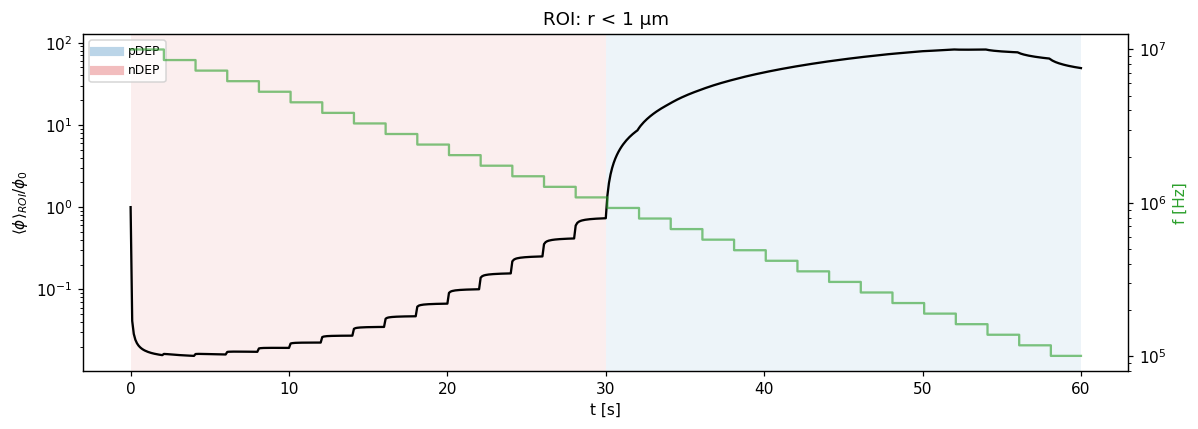

In [6]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t, enr, "k")
ax.set(xlabel="t [s]", ylabel=r"$\langle\phi\rangle_{ROI}/\phi_0$", yscale="log",
       title=f"ROI: r < {r_ROI*1e6:g} µm")
for k, f in enumerate(freqs):           # sombreado pDEP / nDEP por tramo
    c = "C0" if A_DEP(f) > 0 else "C3"
    ax.axvspan(k * t_step, (k + 1) * t_step, color=c, alpha=0.08, lw=0)
ax2 = ax.twinx()
ax2.step(t, res["f"], where="post", color="C2", alpha=0.6)
ax2.set_yscale("log"); ax2.set_ylabel("f [Hz]", color="C2")
ax.plot([], [], color="C0", alpha=0.3, lw=6, label="pDEP")
ax.plot([], [], color="C3", alpha=0.3, lw=6, label="nDEP")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

### Mapa $\phi(r,t)$ y perfiles al final de cada frecuencia

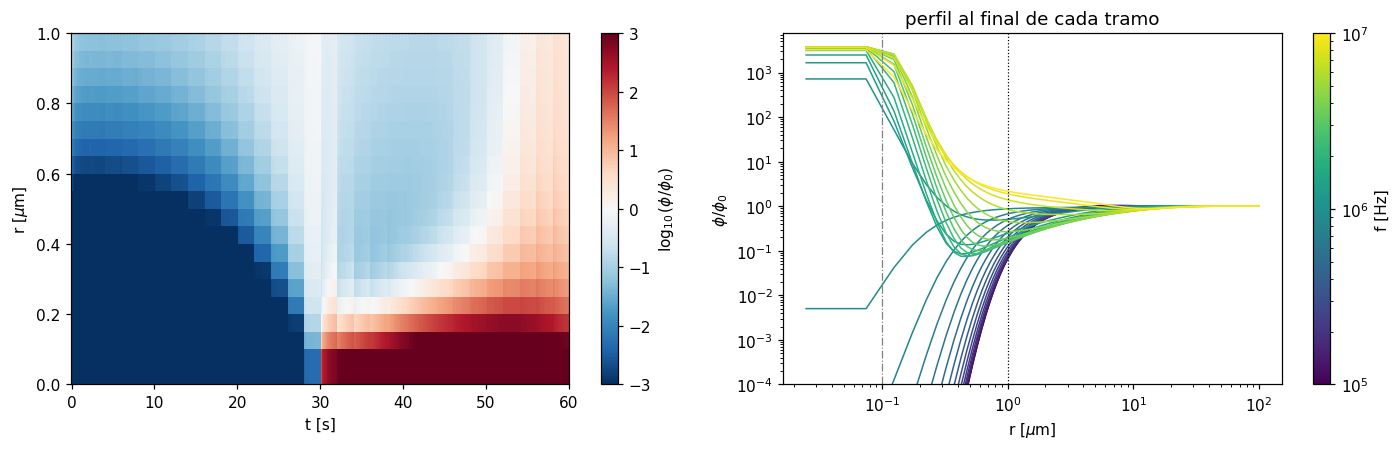

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
rmax_plot = 10 * r_c
m = r < rmax_plot
im = ax[0].pcolormesh(t, r[m] * 1e6, np.log10(np.maximum(P[m], 1e-12) / phi0),
                      shading="auto", cmap="RdBu_r", vmin=-3, vmax=3)
fig.colorbar(im, ax=ax[0], label=r"$\log_{10}(\phi/\phi_0)$")
ax[0].axhline(r_ROI * 1e6, color="k", ls=":", lw=0.8)
ax[0].set(xlabel="t [s]", ylabel=r"r [$\mu$m]")

cols = plt.cm.viridis(np.linspace(0, 1, len(freqs)))
for k in range(len(freqs)):
    ax[1].plot(r * 1e6, res["P_end"][:, k] / phi0, color=cols[k], lw=1)
ax[1].axvline(r_ROI * 1e6, color="k", ls=":", lw=0.8)
ax[1].axvline(r_c * 1e6, color="gray", ls="-.", lw=0.8)
ax[1].set(xscale="log", yscale="log", xlabel=r"r [$\mu$m]", ylabel=r"$\phi/\phi_0$",
          ylim=(1e-4, 2 * phi_max / phi0), title="perfil al final de cada tramo")
sm = plt.cm.ScalarMappable(cmap="viridis", norm=plt.matplotlib.colors.LogNorm(freqs.min(), freqs.max()))
fig.colorbar(sm, ax=ax[1], label="f [Hz]")
plt.tight_layout(); plt.show()

### Enriquecimiento al final de cada tramo vs. equilibrio

El equilibrio (Fermi-Dirac, $t\to\infty$ a frecuencia fija) indica si 2 s bastan para relajar. Si la curva simulada se separa del equilibrio, la respuesta medida depende de la historia del barrido (orden de frecuencias, $t_{step}$).

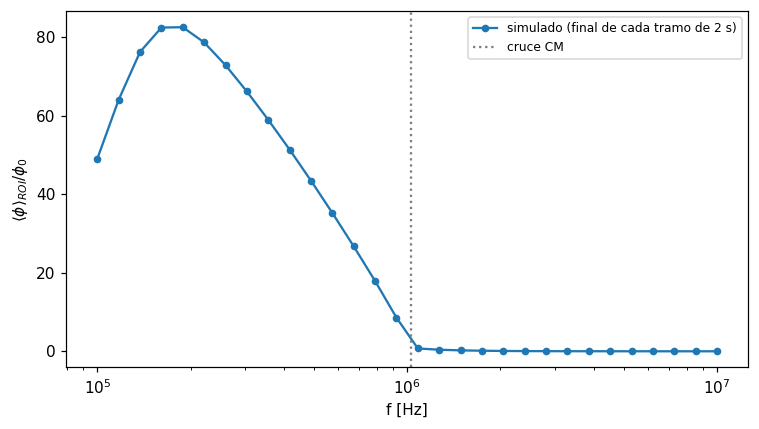

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(freqs, enr_end, "o-", ms=4, label=f"simulado (final de cada tramo de {t_step:g} s)")
#ax.plot(freqs, enr_eq, "k--", label="equilibrio a cada frecuencia")
ax.set_xscale("log")
ax.axvline(f_cross, color="gray", ls=":", label="cruce CM")
ax.set(xlabel="f [Hz]", ylabel=r"$\langle\phi\rangle_{ROI}/\phi_0$")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 4. Efecto del apantallamiento (comparación con $S=1$)

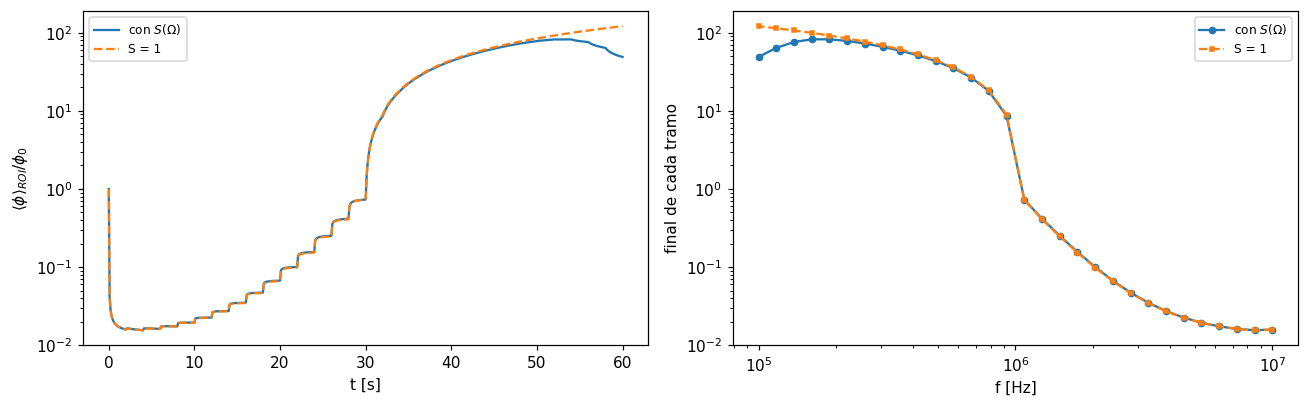

In [9]:
res0 = run_sweep(freqs, screening=False)
enr0, _ = roi_stats(res0["fp"], res0["P"])
enr0_end, _ = roi_stats(res0["fp"], res0["P_end"])

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(t, enr, label=r"con $S(\Omega)$")
ax[0].plot(res0["t"], enr0, "--", label="S = 1")
ax[0].set(xlabel="t [s]", ylabel=r"$\langle\phi\rangle_{ROI}/\phi_0$", yscale="log"); ax[0].legend(fontsize=8)
ax[1].loglog(freqs, enr_end, "o-", ms=4, label=r"con $S(\Omega)$")
ax[1].loglog(freqs, enr0_end, "s--", ms=3, label="S = 1")
ax[1].set(xlabel="f [Hz]", ylabel="final de cada tramo"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Convergencia numérica (malla doble)

In [10]:
res2 = run_sweep(freqs, screening=True, N=2 * N)
enr2_end, _ = roi_stats(res2["fp"], res2["P_end"])
err = np.abs(enr2_end - enr_end) / np.maximum(enr2_end, 1e-30)
ok = enr2_end > 1e-2          # ignorar tramos con la ROI prácticamente vacía (error relativo sin sentido)
print("diferencia relativa N vs 2N en el enriquecimiento final de cada tramo (ROI no vacía):")
print(f"  máx = {err[ok].max():.2e}  (en f = {freqs[ok][err[ok].argmax()]:.3g} Hz),  mediana = {np.median(err[ok]):.2e}")
for f_, e1, e2 in zip(freqs[~ok], enr_end[~ok], enr2_end[~ok]):
    print(f"  f = {f_:.3g} Hz: ROI casi vacía, N -> {e1:.2e}, 2N -> {e2:.2e}")

diferencia relativa N vs 2N en el enriquecimiento final de cada tramo (ROI no vacía):
  máx = 3.04e-01  (en f = 1e+05 Hz),  mediana = 5.24e-02


## 6. Exportar resultados

In [11]:
tabla = np.column_stack([freqs, K_CM(freqs).real, S(freqs), U_DEP(r_c, freqs) / kT, enr_end, enr_eq])
np.savetxt("barrido_dep.csv", tabla, delimiter=",",
           header="f_Hz,ReK,S,U_rc_kT,enr_ROI_final,enr_ROI_equilibrio", comments="")
np.savez_compressed("barrido_dep.npz", r=r, t=t, phi=P, f_t=res["f"], freqs=freqs,
                    phi_end=res["P_end"], phi_eq=res["P_eq"], enr_ROI=enr, n_ROI_per_m=n_roi)
print("guardado: barrido_dep.csv, barrido_dep.npz")

guardado: barrido_dep.csv, barrido_dep.npz
